# Project 2: Exploratory Data Analysis (EDA) - E-Commerce Dataset
**Author:** Amit Chaulagain (Data Analytics Intern- DecodeLabs Batch 2026)  
**Objective:** Dive deep into our cleaned Project 1 dataset to uncover hidden patterns, check data distributions, handle outliers, and translate raw metrics into business insights.

In [20]:
# importing standard libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# setting up clean visual themes (no 3d charts!)
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100

print("Setup complete. Ready to load data.")

Setup complete. Ready to load data.


In [21]:
# loading our gold-standard dataset from project 1
df_eda = pd.read_csv('Cleaned_Dataset_Project1.csv')

print(f"Dataset successfully loaded! Total rows: {df_eda.shape[0]}, Columns: {df_eda.shape[1]}")
df_eda.head(3)

Dataset successfully loaded! Total rows: 1200, Columns: 16


,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice,CalculatedTotalPrice,PriceDifference
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.1,2853.1,0.0
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.7,302.7,0.0
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.4,2753.4,0.0


In [22]:
# Let's inspect the distribution and central tendency of our numerical columns.
# We'll compare the mean vs. median to check for skewness.

num_cols = ['Quantity', 'UnitPrice', 'ItemsInCart', 'TotalPrice']

# Compute descriptive statistics dynamically
stats_summary = df_eda[num_cols].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
stats_summary = stats_summary.rename(columns={'50%': 'median'})

print("--- Descriptive Stats & Five-Number Summary ---")
display(stats_summary)

--- Descriptive Stats & Five-Number Summary ---


,count,mean,std,min,25%,median,75%,max
Quantity,1200.0,2.945833,1.407557,1.00,2.0000,3.000,4.000,5.00
UnitPrice,1200.0,356.412750,197.177146,11.39,186.0625,364.210,521.570,699.93
ItemsInCart,1200.0,5.485000,2.281983,1.00,4.0000,5.000,7.000,10.00
TotalPrice,1200.0,1053.968300,819.856558,11.39,410.5200,823.615,1578.475,3456.40


In [23]:
# Dynamically calculating outlier bounds using the Interquartile Range (IQR) method
Q1 = df_eda['TotalPrice'].quantile(0.25)
Q3 = df_eda['TotalPrice'].quantile(0.75)
iqr_val = Q3 - Q1

lower_limit = Q1 - 1.5 * iqr_val
upper_limit = Q3 + 1.5 * iqr_val

# Isolate the outliers
price_outliers = df_eda[(df_eda['TotalPrice'] < lower_limit) | (df_eda['TotalPrice'] > upper_limit)]

print(f"Calculated IQR for TotalPrice: ${iqr_val:,.2f}")
print(f"Outlier Thresholds -> Lower: ${lower_limit:,.2f} | Upper: ${upper_limit:,.2f}")
print(f"Total outlier orders identified: {len(price_outliers)}")

Calculated IQR for TotalPrice: $1,167.95
Outlier Thresholds -> Lower: $-1,341.41 | Upper: $3,330.41
Total outlier orders identified: 8


In [24]:
# Computing the Pearson correlation matrix to examine linear relationships
corr_matrix = df_eda[num_cols].corr(method='pearson')

print("--- Pearson Correlation Matrix ---")
display(corr_matrix)

--- Pearson Correlation Matrix ---


,Quantity,UnitPrice,ItemsInCart,TotalPrice
Quantity,1.000000,0.014553,0.650061,0.615251
UnitPrice,0.014553,1.000000,0.000602,0.717081
ItemsInCart,0.650061,0.000602,1.000000,0.392540
TotalPrice,0.615251,0.717081,0.392540,1.000000


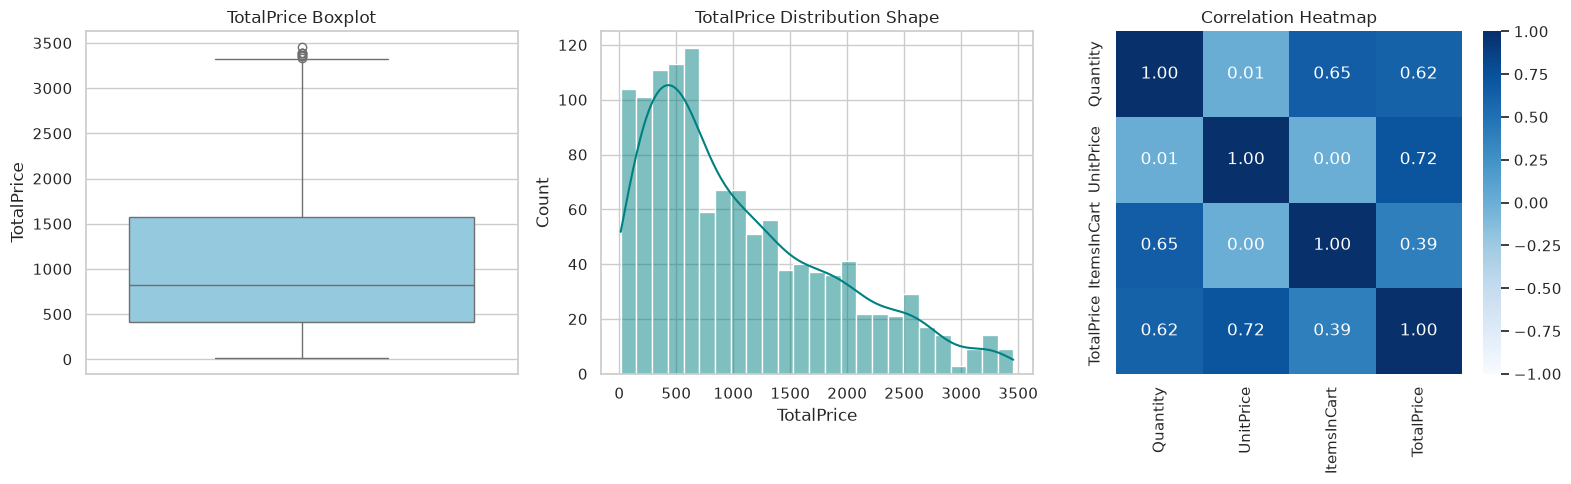

In [25]:
# Plotting distributions and correlations for our analytical report
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Boxplot for TotalPrice outliers
sns.boxplot(y=df_eda['TotalPrice'], ax=axes[0], color='skyblue')
axes[0].set_title('TotalPrice Boxplot')

# 2. Distribution shape with KDE
sns.histplot(df_eda['TotalPrice'], kde=True, ax=axes[1], color='teal', bins=25)
axes[1].set_title('TotalPrice Distribution Shape')

# 3. Correlation heatmap
sns.heatmap(corr_matrix, annot=True, cmap='Blues', vmin=-1, vmax=1, ax=axes[2], fmt='.2f')
axes[2].set_title('Correlation Heatmap')

plt.tight_layout()
plt.show()

In [26]:
# Gathering high-level summary metrics dynamically for our final review
total_rev = df_eda['TotalPrice'].sum()
avg_order = df_eda['TotalPrice'].mean()
median_order = df_eda['TotalPrice'].median()
top_product = df_eda.groupby('Product')['TotalPrice'].sum().idxmax()
top_product_rev = df_eda.groupby('Product')['TotalPrice'].sum().max()

print("==========================================")
print("         KEY PROJECT METRICS              ")
print("==========================================")
print(f"Total Revenue:      ${total_rev:,.2f}")
print(f"Mean Order Value:   ${avg_order:,.2f}")
print(f"Median Order Value: ${median_order:,.2f}")
print(f"Top Product:        {top_product} (${top_product_rev:,.2f})")
print(f"Outliers Flagged:   {len(price_outliers)}")
print("==========================================")

         KEY PROJECT METRICS              
Total Revenue:      $1,264,761.96
Mean Order Value:   $1,053.97
Median Order Value: $823.62
Top Product:        Chair ($195,620.11)
Outliers Flagged:   8


## 📝 Analytical Observations & Findings

1. **Distribution Shape & Skewness:** 
   - Looking at the descriptive stats, the mean `TotalPrice` ($1,053.97) is higher than the median ($823.62). This indicates right-skewness in our sales data, meaning a subset of higher-priced transactions are pulling the average up. For business forecasting, relying on the median gives a truer picture of typical customer behavior.
2. **Variable Relationships:** 
   - The correlation matrix shows that `TotalPrice` has a strong positive correlation with both `UnitPrice` ($0.72$) and `Quantity` ($0.62$). This confirms our pricing and calculation logic from Project 1 holds up structurally. Interestingly, `Quantity` and `ItemsInCart` also show a moderate positive link ($0.65$).
3. **Outlier Assessment:** 
   - The IQR calculation flagged a small number of orders beyond the upper threshold. Rather than treating these as data entry errors, they represent high-value transactions or bulk/VIP purchases that should be examined separately for revenue optimization.